# Projet 13 — Segmentation des clients selon leur valeur financière
**Jeu de données :** UCI *Online Retail* (id 352) — transactions d'un e-commerçant britannique, 01/12/2010 → 09/12/2011
**Méthodes :** K-means, classification ascendante hiérarchique (CHA, Ward), mélanges gaussiens (GMM)
**Question :** *Peut-on regrouper les clients en segments homogènes de valeur financière, stables et actionnables,
afin de prioriser les actions commerciales (fidélisation, réactivation, maîtrise des coûts) ?*

Exécution Google Colab : importer `Online Retail.xlsx` (ou laisser `ucimlrepo` le télécharger),
puis exécuter les cellules dans l'ordre. Tout est reproductible (graine = 42).

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Configuration

In [6]:
import io
import json
import os
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# Montage de Google Drive (ignoré hors Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

DATA_PATH = "/content/drive/MyDrive/projet 13/Online Retail.xlsx"   # chemin Google Drive (None = recherche automatique)
FIG_DIR, OUT_DIR = "figures", "outputs"
K_RANGE = range(2, 11)                # nombres de clusters testés
K_FINAL = 4                           # fixé après comparaison des critères (section 6)
N_BOOT = 30                           # répétitions pour la stabilité
# Régularisation du GMM : les clients à Frequency = 1 ont des valeurs identiques -> covariances singulières
# (BIC aberrant). reg_covar = 1e-2 évite cet effondrement des composantes.
REG_COVAR = 1e-2
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#1F4E79", "#2E9E8F", "#E9A23B", "#C8553D", "#7A5C99", "#6B8E23"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
RES = {}  # dictionnaire de résultats exportés (utilisé pour le rapport et la présentation)


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Chargement et description des données

In [9]:
def trouver_fichier():
    """Cherche le fichier Online Retail quel que soit son nom exact (Online Retail.xlsx, .xlxs, .xls, .csv, .zip)."""
    import glob
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    dossiers = [".", "/content", "/content/drive/MyDrive", os.path.expanduser("~")]
    exts = (".xlsx", ".xlxs", ".xls", ".csv", ".zip")
    for d in dossiers:
        for f in sorted(glob.glob(os.path.join(d, "*"))):
            nom = os.path.basename(f).lower().replace("_", " ").replace("-", " ")
            if "online" in nom and "retail" in nom and nom.endswith(exts):
                return f
    return None


def charger_donnees():
    """Lit le fichier local ; s'il est absent, corrompu ou invalide, télécharge depuis l'UCI via `ucimlrepo`."""
    chemin = trouver_fichier()
    if chemin is not None:
        print("Tentative d'utilisation du fichier :", chemin)
        try:
            if chemin.lower().endswith(".zip"):
                with zipfile.ZipFile(chemin) as z:
                    membre = [m for m in z.namelist() if m.lower().endswith((".xlsx", ".xlxs", ".xls", ".csv"))][0]
                    contenu = io.BytesIO(z.read(membre))
                    chemin = membre
            else:
                with open(chemin, "rb") as fh:
                    contenu = io.BytesIO(fh.read())

            if chemin.lower().endswith(".csv"):
                return pd.read_csv(contenu, encoding="latin-1")
            return pd.read_excel(contenu, engine="openpyxl")
        except Exception as e:
            print(f"Le fichier local n'a pas pu être lu ({e}). Chargement alternatif via l'API UCI...")

    try:
        try:
            from ucimlrepo import fetch_ucirepo
        except ImportError:
            print("Installation du paquet ucimlrepo requis...")
            import subprocess
            import sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
            from ucimlrepo import fetch_ucirepo

        d = fetch_ucirepo(id=352)
        return d.data.original
    except Exception as e:
        raise FileNotFoundError("Fichier local illisible et téléchargement UCI impossible. Veuillez vérifier le fichier.") from e


raw = charger_donnees()
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)
print("Dimensions :", raw.shape)
print(raw.dtypes)
display(raw.head()) if "display" in globals() else print(raw.head())

RES["n_lignes_brutes"] = int(len(raw))
RES["periode"] = [str(raw.InvoiceDate.min()), str(raw.InvoiceDate.max())]
RES["n_factures_brutes"] = int(raw.InvoiceNo.nunique())
RES["n_clients_bruts"] = int(raw.CustomerID.nunique())
RES["n_produits"] = int(raw.StockCode.nunique())
RES["n_pays"] = int(raw.Country.nunique())

Tentative d'utilisation du fichier : /content/drive/MyDrive/projet 13/Online Retail.xlsx
Le fichier local n'a pas pu être lu ("There is no item named '[Content_Types].xml' in the archive"). Chargement alternatif via l'API UCI...
Installation du paquet ucimlrepo requis...
Dimensions : (541909, 8)
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 

### Dictionnaire des variables
| Variable | Description |
|---|---|
| InvoiceNo | n° de facture (préfixe **C** = annulation / avoir) |
| StockCode | code produit |
| Description | libellé produit |
| Quantity | quantités (négatives pour les annulations) |
| InvoiceDate | date-heure de la facture |
| UnitPrice | prix unitaire (£) |
| CustomerID | identifiant client (5 chiffres) — **manquant pour 25 % des lignes** |
| Country | pays du client |

## 2. Audit qualité et nettoyage

In [10]:
audit = {}
audit["lignes_sans_client"] = int(raw.CustomerID.isna().sum())
audit["part_lignes_sans_client_%"] = round(100 * raw.CustomerID.isna().mean(), 1)
audit["lignes_annulations (C…)"] = int(raw.InvoiceNo.str.startswith("C").sum())
audit["quantite<=0"] = int((raw.Quantity <= 0).sum())
audit["prix<=0"] = int((raw.UnitPrice <= 0).sum())
audit["doublons_exacts"] = int(raw.duplicated().sum())
CODES_NON_PRODUITS = ["POST", "D", "M", "DOT", "BANK CHARGES", "CRUK", "S", "AMAZONFEE", "B", "PADS"]
audit["lignes_codes_non_produits"] = int(raw.StockCode.isin(CODES_NON_PRODUITS).sum())
print(pd.Series(audit))
RES["audit"] = audit

lignes_sans_client           135080.0
part_lignes_sans_client_%        24.9
lignes_annulations (C…)        9288.0
quantite<=0                   10624.0
prix<=0                        2517.0
doublons_exacts                5268.0
lignes_codes_non_produits      2771.0
dtype: float64


In [11]:
# Étape 1 : doublons exacts
df = raw.drop_duplicates().copy()
n1 = len(df)
# Étape 2 : lignes sans identifiant client (non segmentables)
df = df[df.CustomerID.notna()].copy()
df["CustomerID"] = df.CustomerID.astype(int)
n2 = len(df)
# Étape 3 : codes « frais » (port, commission, ajustements) — pas des achats de produits
df = df[~df.StockCode.isin(CODES_NON_PRODUITS)]
n3 = len(df)
# Étape 4 : séparation ventes / annulations
df["Montant"] = df.Quantity * df.UnitPrice
annul = df[df.InvoiceNo.str.startswith("C")].copy()
ventes = df[(~df.InvoiceNo.str.startswith("C")) & (df.Quantity > 0) & (df.UnitPrice > 0)].copy()
RES["flux_nettoyage"] = {"brut": len(raw), "apres_doublons": n1, "avec_client": n2, "hors_codes_frais": n3,
                         "lignes_ventes": len(ventes), "lignes_annulations": len(annul)}
print(RES["flux_nettoyage"])
print(f"Clients avec ≥1 achat : {ventes.CustomerID.nunique()}")
RES["n_clients_ventes"] = int(ventes.CustomerID.nunique())
RES["n_factures_ventes"] = int(ventes.InvoiceNo.nunique())
RES["ca_total"] = float(ventes.Montant.sum())
RES["ca_annule"] = float(-annul.Montant.sum())

{'brut': 541909, 'apres_doublons': 536641, 'avec_client': 401604, 'hors_codes_frais': 399823, 'lignes_ventes': 391283, 'lignes_annulations': 8507}
Clients avec ≥1 achat : 4334


## 3. Analyse exploratoire

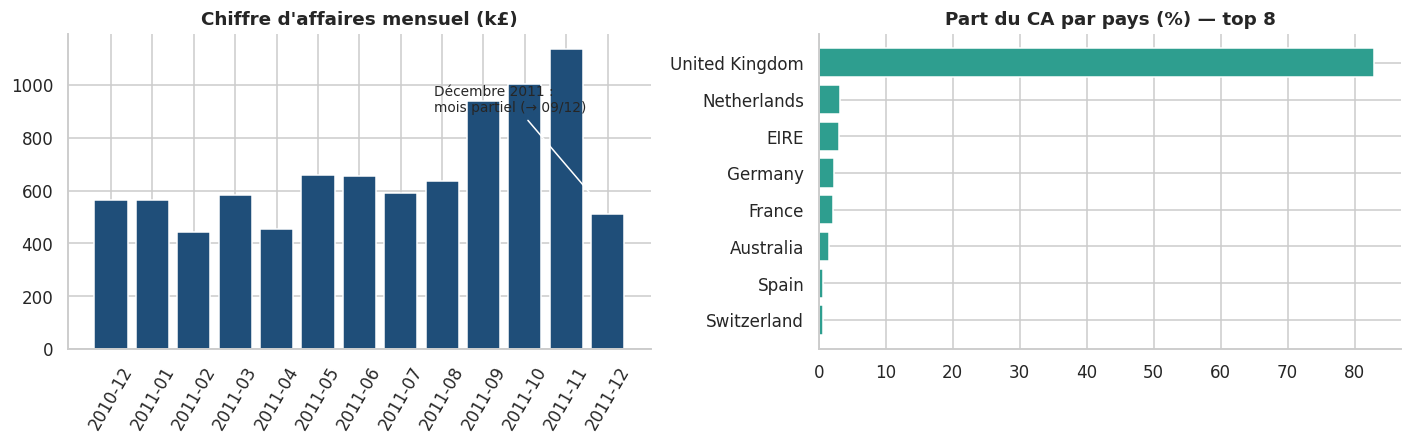

In [14]:
ventes["InvoiceDate"] = pd.to_datetime(ventes["InvoiceDate"])
ventes["Mois"] = ventes.InvoiceDate.dt.to_period("M")
ca_mois = ventes.groupby("Mois").Montant.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ca_mois.index = ca_mois.index.astype(str)
ax[0].bar(ca_mois.index, ca_mois.values / 1e3, color=PALETTE[0])
ax[0].set_title("Chiffre d'affaires mensuel (k£)")
ax[0].tick_params(axis="x", rotation=60)
ax[0].annotate("Décembre 2011 :\nmois partiel (→ 09/12)", xy=(len(ca_mois) - 1, ca_mois.iloc[-1] / 1e3),
               xytext=(len(ca_mois) - 5.2, 900), arrowprops=dict(arrowstyle="->"), fontsize=9)
pays = ventes.groupby("Country").Montant.sum().sort_values(ascending=False)
top = pays.head(8) / pays.sum() * 100
ax[1].barh(top.index[::-1], top.values[::-1], color=PALETTE[1])
ax[1].set_title("Part du CA par pays (%) — top 8")
savefig("01_eda_ca_mensuel_pays")
RES["part_uk_%"] = float(100 * pays["United Kingdom"] / pays.sum())
RES["ca_mois"] = {k: float(v) for k, v in ca_mois.items()}

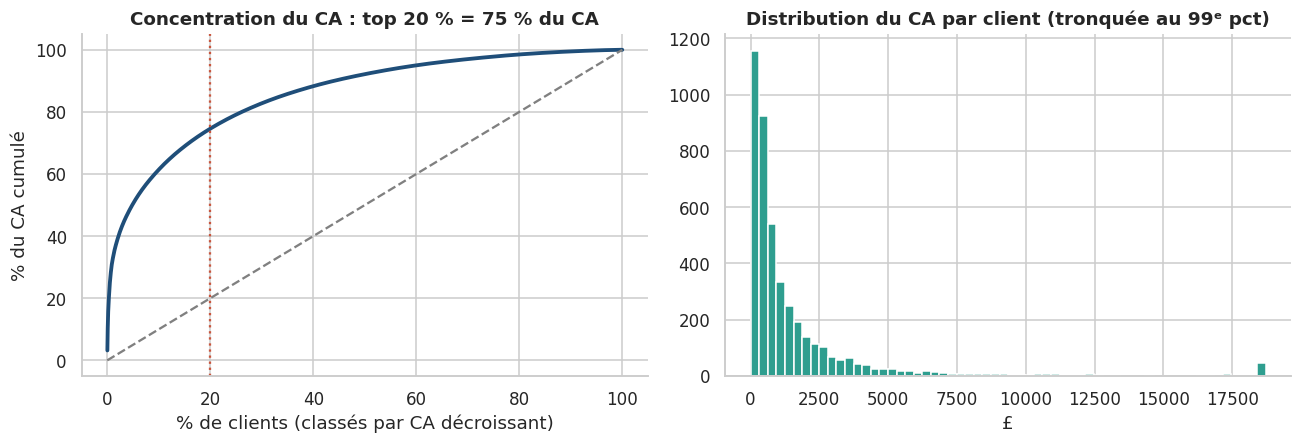

{'part_ca_top20_%': 74.6, 'part_ca_top10_%': 61.4, 'part_ca_top1_%': 32.0, 'gini_ca_clients': 0.7}


In [15]:
# Concentration du chiffre d'affaires (courbe de Lorenz / Pareto) au niveau client
ca_client = ventes.groupby("CustomerID").Montant.sum().sort_values(ascending=False)
cum = ca_client.cumsum() / ca_client.sum()
x = np.arange(1, len(ca_client) + 1) / len(ca_client)
RES["part_ca_top20_%"] = float(100 * cum.iloc[int(0.2 * len(cum)) - 1])
RES["part_ca_top10_%"] = float(100 * cum.iloc[int(0.1 * len(cum)) - 1])
RES["part_ca_top1_%"] = float(100 * cum.iloc[int(0.01 * len(cum)) - 1])
lorenz = np.sort(ca_client.values).cumsum() / ca_client.sum()
RES["gini_ca_clients"] = float(1 - 2 * (np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(lorenz, dx=1 / len(lorenz)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(x * 100, cum.values * 100, color=PALETTE[0], lw=2.5)
ax[0].plot([0, 100], [0, 100], "--", color="grey")
ax[0].axvline(20, color=PALETTE[3], ls=":")
ax[0].set_xlabel("% de clients (classés par CA décroissant)")
ax[0].set_ylabel("% du CA cumulé")
ax[0].set_title(f"Concentration du CA : top 20 % = {RES['part_ca_top20_%']:.0f} % du CA")
ax[1].hist(ca_client.clip(upper=ca_client.quantile(.99)), bins=60, color=PALETTE[1])
ax[1].set_title("Distribution du CA par client (tronquée au 99ᵉ pct)")
ax[1].set_xlabel("£")
savefig("02_eda_concentration_ca")
print({k: round(v, 1) for k, v in RES.items() if k.startswith("part_ca") or k == "gini_ca_clients"})

## 4. Ingénierie des variables (profil financier client)
On se place à une **date de référence** = lendemain de la dernière facture (10/12/2011).

| Variable | Définition | Lecture financière |
|---|---|---|
| Recency | jours depuis le dernier achat | risque d'attrition |
| Frequency | nombre de factures distinctes | récurrence |
| Monetary | CA cumulé (£) | valeur historique |
| AvgBasket | Monetary / Frequency | panier moyen |
| ReturnRate | montant annulé / montant acheté | coût de service / risque |
| NbProducts | nombre de références distinctes | diversification |

In [16]:
def construire_features(v, a, snapshot):
    g = v.groupby("CustomerID")
    f = pd.DataFrame({
        "Recency": (snapshot - g.InvoiceDate.max()).dt.days,
        "Frequency": g.InvoiceNo.nunique(),
        "Monetary": g.Montant.sum(),
        "NbProducts": g.StockCode.nunique(),
        "Anciennete": (snapshot - g.InvoiceDate.min()).dt.days,
    })
    f["AvgBasket"] = f.Monetary / f.Frequency
    annule = (-a.groupby("CustomerID").Montant.sum()).reindex(f.index).fillna(0)
    f["ReturnRate"] = (annule / f.Monetary).clip(0, 1)
    return f


SNAPSHOT = ventes.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
feat = construire_features(ventes, annul, SNAPSHOT)
print(feat.describe().T.round(2))
RES["describe"] = feat.describe().T.round(2).to_dict()
RES["snapshot"] = str(SNAPSHOT.date())

             count     mean      std   min    25%     50%      75%        max
Recency     4334.0    92.23   100.18  0.00   17.0   50.00   142.00     373.00
Frequency   4334.0     4.25     7.64  1.00    1.0    2.00     5.00     206.00
Monetary    4334.0  2017.52  8920.36  3.75  304.3  663.71  1631.62  279138.02
NbProducts  4334.0    61.43    85.31  1.00   16.0   35.00    77.00    1786.00
Anciennete  4334.0   222.83   117.84  0.00  112.0  248.00   326.00     373.00
AvgBasket   4334.0   415.67  1800.86  3.75  177.2  289.77   423.77   84236.25
ReturnRate  4334.0     0.02     0.08  0.00    0.0    0.00     0.01       1.00


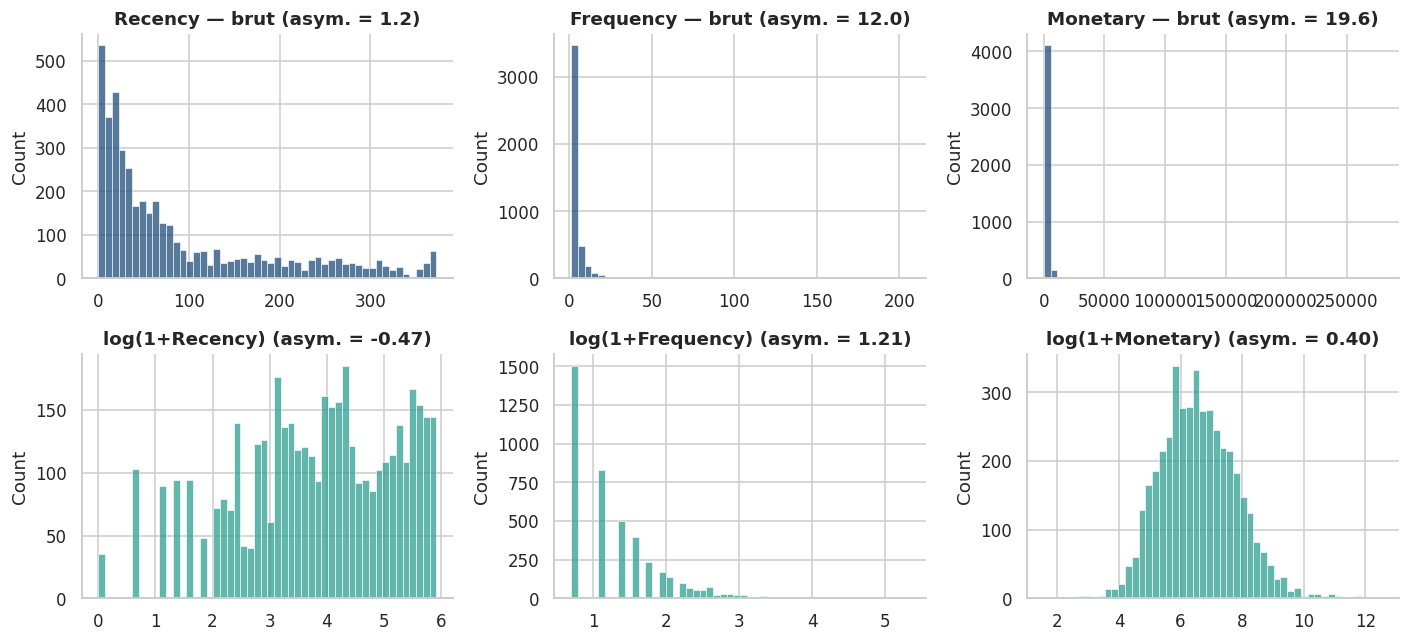

In [17]:
# Asymétrie avant / après transformation logarithmique
core = ["Recency", "Frequency", "Monetary"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(core):
    sns.histplot(feat[c], bins=50, ax=ax[0, j], color=PALETTE[0])
    ax[0, j].set_title(f"{c} — brut (asym. = {feat[c].skew():.1f})")
    sns.histplot(np.log1p(feat[c]), bins=50, ax=ax[1, j], color=PALETTE[1])
    ax[1, j].set_title(f"log(1+{c}) (asym. = {np.log1p(feat[c]).skew():.2f})")
    ax[0, j].set_xlabel(""); ax[1, j].set_xlabel("")
savefig("03_distributions_log")
RES["skew_brut"] = {c: float(feat[c].skew()) for c in core}
RES["skew_log"] = {c: float(np.log1p(feat[c]).skew()) for c in core}

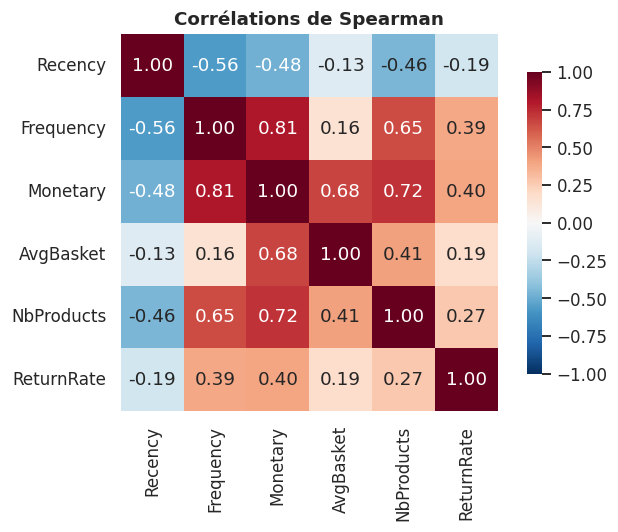

In [18]:
# Corrélations (Spearman, robuste aux valeurs extrêmes)
cols_all = ["Recency", "Frequency", "Monetary", "AvgBasket", "NbProducts", "ReturnRate"]
corr = feat[cols_all].corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Corrélations de Spearman")
savefig("04_correlations")
RES["corr"] = corr.round(2).to_dict()

## 5. Pré-traitement pour le clustering
* Transformation `log(1+x)` (réduit l'asymétrie, limite le poids des clients extrêmes).
* Standardisation (moyenne 0, écart-type 1) : indispensable pour les méthodes basées sur les distances.
* **Modèle principal : RFM** (3 variables, interprétables). **Variante RFM+** (ajout panier moyen et taux d'annulation) pour tester la robustesse.

In [19]:
def preparer(frame, cols):
    X = np.log1p(frame[cols].astype(float))
    sc = StandardScaler().fit(X)
    return sc.transform(X), sc


X, scaler = preparer(feat, core)
X_plus, _ = preparer(feat, ["Recency", "Frequency", "Monetary", "AvgBasket", "ReturnRate"])
n = len(X)
print("Matrice RFM :", X.shape)

Matrice RFM : (4334, 3)


## 6. Choix du nombre de segments — comparaison des trois méthodes

In [20]:
lignes = []
Z = linkage(X, method="ward")
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=SEED, reg_covar=REG_COVAR).fit(X)
    lab_w = fcluster(Z, k, criterion="maxclust") - 1
    lab_g = gm.predict(X)
    lignes.append({
        "K": k,
        "KM_inertie": km.inertia_,
        "KM_silhouette": silhouette_score(X, km.labels_),
        "KM_CH": calinski_harabasz_score(X, km.labels_),
        "KM_DB": davies_bouldin_score(X, km.labels_),
        "CHA_silhouette": silhouette_score(X, lab_w),
        "CHA_CH": calinski_harabasz_score(X, lab_w),
        "CHA_DB": davies_bouldin_score(X, lab_w),
        "GMM_BIC": gm.bic(X), "GMM_AIC": gm.aic(X),
        "GMM_silhouette": silhouette_score(X, lab_g),
    })
crit = pd.DataFrame(lignes).set_index("K")
print(crit.round(3))
crit.round(4).to_csv(f"{OUT_DIR}/criteres_selection_K.csv")
RES["criteres"] = crit.round(4).reset_index().to_dict(orient="list")
coph, _ = cophenet(Z, pdist(X))
RES["cophenetic_ward"] = float(coph)

    KM_inertie  KM_silhouette     KM_CH  KM_DB  CHA_silhouette    CHA_CH  \
K                                                                          
2     6481.795          0.434  4357.679  0.891           0.437  3652.694   
3     4871.387          0.342  3614.340  1.038           0.269  2972.749   
4     3956.194          0.337  3300.199  1.014           0.279  2773.655   
5     3325.470          0.316  3149.199  0.996           0.271  2608.352   
6     2871.007          0.315  3054.479  1.017           0.234  2459.409   
7     2571.594          0.309  2925.057  0.976           0.243  2373.192   
8     2357.243          0.300  2790.745  0.996           0.240  2375.018   
9     2181.932          0.293  2680.936  1.028           0.236  2252.168   
10    2019.840          0.277  2612.258  1.022           0.231  2163.732   

    CHA_DB    GMM_BIC    GMM_AIC  GMM_silhouette  
K                                                 
2    0.846  29146.372  29025.261           0.357  
3    1.225

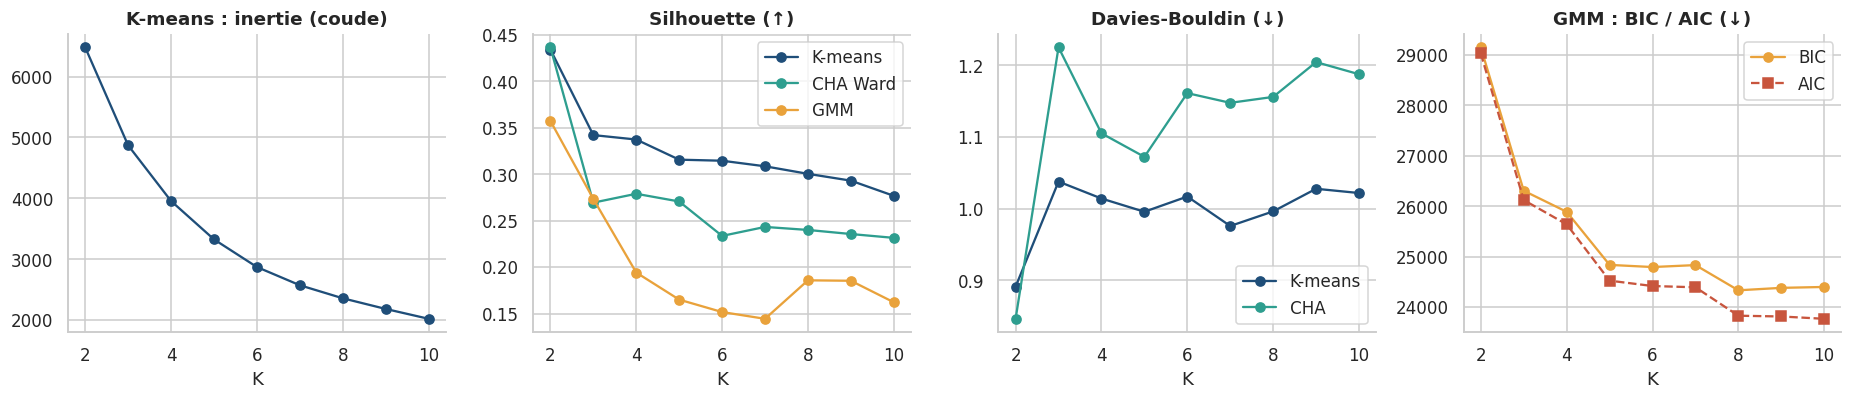

In [21]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
ax[0].plot(crit.index, crit.KM_inertie, "o-", color=PALETTE[0]); ax[0].set_title("K-means : inertie (coude)")
for lab, c, col in [("K-means", "KM_silhouette", PALETTE[0]), ("CHA Ward", "CHA_silhouette", PALETTE[1]),
                    ("GMM", "GMM_silhouette", PALETTE[2])]:
    ax[1].plot(crit.index, crit[c], "o-", label=lab, color=col)
ax[1].set_title("Silhouette (↑)"); ax[1].legend()
ax[2].plot(crit.index, crit.KM_DB, "o-", label="K-means", color=PALETTE[0])
ax[2].plot(crit.index, crit.CHA_DB, "o-", label="CHA", color=PALETTE[1])
ax[2].set_title("Davies-Bouldin (↓)"); ax[2].legend()
ax[3].plot(crit.index, crit.GMM_BIC, "o-", color=PALETTE[2], label="BIC")
ax[3].plot(crit.index, crit.GMM_AIC, "s--", color=PALETTE[3], label="AIC")
ax[3].set_title("GMM : BIC / AIC (↓)"); ax[3].legend()
for a in ax: a.set_xlabel("K")
savefig("05_criteres_selection_K")

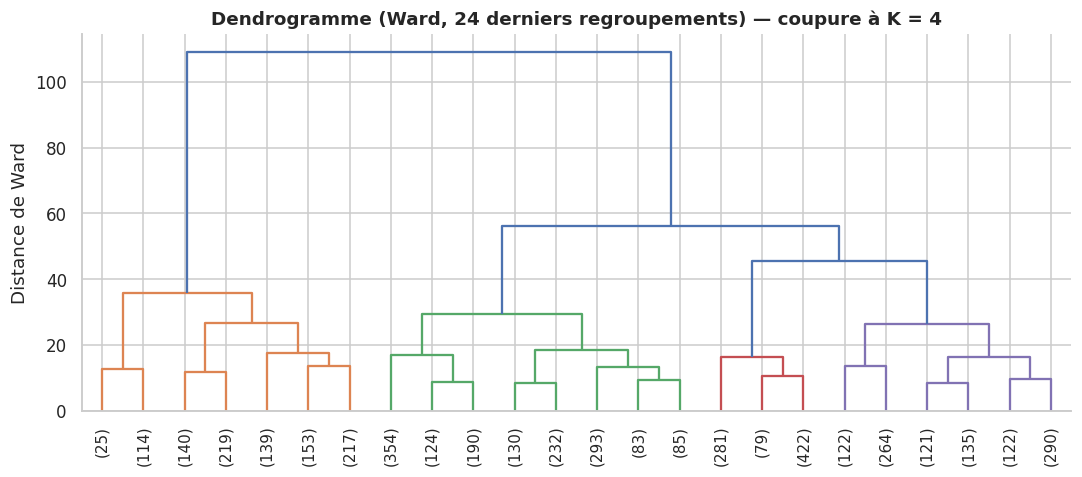

In [22]:
# Dendrogramme (Ward) tronqué
plt.figure(figsize=(10, 4.5))
dendrogram(Z, truncate_mode="lastp", p=24, show_leaf_counts=True, leaf_rotation=90, color_threshold=Z[-(K_FINAL - 1), 2])
plt.title(f"Dendrogramme (Ward, 24 derniers regroupements) — coupure à K = {K_FINAL}")
plt.ylabel("Distance de Ward")
savefig("06_dendrogramme")

### Décision sur K
La silhouette est maximale pour un K très faible (séparation « actifs / inactifs » dominée par la récence),
ce qui est trop pauvre pour l'action commerciale. On retient **K = 4**, compromis entre : (i) un score de
silhouette encore acceptable, (ii) un coude de l'inertie, (iii) la lisibilité métier, (iv) la stabilité (section 8).

## 7. Modèles finaux et comparaison

            Silhouette  Calinski-Harabasz  Davies-Bouldin  Taille min (%)  \
Méthode                                                                     
K-means          0.338           3300.235           1.013          15.874   
CHA (Ward)       0.279           2773.655           1.105          18.043   
GMM              0.194           2270.159           1.579          13.406   

            Taille max (%)  
Méthode                     
K-means             38.071  
CHA (Ward)          34.402  
GMM                 34.564  

ARI entre méthodes :
             K-means  CHA (Ward)    GMM
K-means       1.000       0.368  0.440
CHA (Ward)    0.368       1.000  0.337
GMM           0.440       0.337  1.000


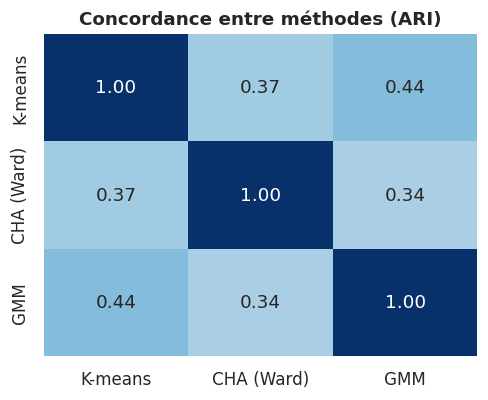

In [23]:
def reordonner(labels, frame):
    """Renumérote les clusters par CA médian décroissant (0 = segment de plus forte valeur)."""
    med = frame.assign(c=labels).groupby("c").Monetary.median().sort_values(ascending=False)
    mapping = {old: new for new, old in enumerate(med.index)}
    return np.array([mapping[l] for l in labels])


km = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(X)
gm = GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=10, random_state=SEED, reg_covar=REG_COVAR).fit(X)
lab = {
    "K-means": reordonner(km.labels_, feat),
    "CHA (Ward)": reordonner(fcluster(Z, K_FINAL, criterion="maxclust") - 1, feat),
    "GMM": reordonner(gm.predict(X), feat),
}
comp = []
for nom, l in lab.items():
    tailles = np.bincount(l)
    comp.append({"Méthode": nom, "Silhouette": silhouette_score(X, l), "Calinski-Harabasz": calinski_harabasz_score(X, l),
                 "Davies-Bouldin": davies_bouldin_score(X, l), "Taille min (%)": 100 * tailles.min() / n,
                 "Taille max (%)": 100 * tailles.max() / n})
comp = pd.DataFrame(comp).set_index("Méthode")
print(comp.round(3))
RES["comparaison"] = comp.round(4).reset_index().to_dict(orient="records")

ari = pd.DataFrame([[adjusted_rand_score(a, b) for b in lab.values()] for a in lab.values()],
                   index=lab.keys(), columns=lab.keys())
print("\nARI entre méthodes :\n", ari.round(3))
RES["ari_methodes"] = ari.round(3).to_dict()
plt.figure(figsize=(4.6, 3.8))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title("Concordance entre méthodes (ARI)")
savefig("07_ari_methodes")

## 8. Stabilité des segments (sous-échantillonnage répété)
À chaque répétition : sous-échantillon de 80 % des clients → nouveau clustering → ARI avec la partition de référence
restreinte au sous-échantillon. ARI proche de 1 = segments reproductibles.

      K-means  CHA (Ward)    GMM
mean    0.961       0.393  0.876
std     0.038       0.105  0.074
min     0.799       0.160  0.608
Stabilité K-means selon K : {2: 0.988, 3: 0.962, 4: 0.95, 5: 0.908, 6: 0.942, 8: 0.768}


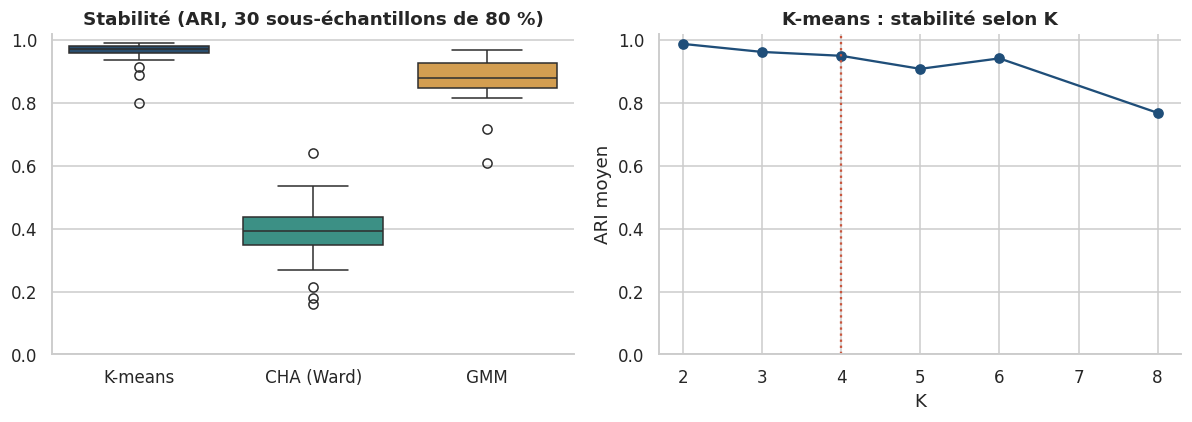

ARI RFM vs RFM+ (K-means) : 0.228


In [24]:
def clusteriser(M, methode, k, seed):
    if methode == "K-means":
        return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(M)
    if methode == "CHA (Ward)":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(M)
    return GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=seed, reg_covar=REG_COVAR).fit(M).predict(M)


stab = {m: [] for m in lab}
for b in range(N_BOOT):
    idx = rng.choice(n, size=int(0.8 * n), replace=False)
    for m in lab:
        stab[m].append(adjusted_rand_score(lab[m][idx], clusteriser(X[idx], m, K_FINAL, SEED + b)))
stab_df = pd.DataFrame(stab)
print(stab_df.describe().round(3).loc[["mean", "std", "min"]])
RES["stabilite_ari"] = {m: {"moy": float(stab_df[m].mean()), "std": float(stab_df[m].std()), "min": float(stab_df[m].min())}
                        for m in stab_df}
# stabilité en fonction de K (K-means)
stabK = {}
for k in [2, 3, 4, 5, 6, 8]:
    ref = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
    vals = []
    for b in range(15):
        idx = rng.choice(n, size=int(0.8 * n), replace=False)
        vals.append(adjusted_rand_score(ref[idx], clusteriser(X[idx], "K-means", k, SEED + b)))
    stabK[k] = float(np.mean(vals))
RES["stabilite_vs_K_kmeans"] = stabK
print("Stabilité K-means selon K :", {k: round(v, 3) for k, v in stabK.items()})

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=stab_df, palette=PALETTE[:3], ax=ax[0])
ax[0].set_title(f"Stabilité (ARI, {N_BOOT} sous-échantillons de 80 %)"); ax[0].set_ylim(0, 1.02)
ax[1].plot(list(stabK), list(stabK.values()), "o-", color=PALETTE[0])
ax[1].axvline(K_FINAL, color=PALETTE[3], ls=":"); ax[1].set_ylim(0, 1.02)
ax[1].set_title("K-means : stabilité selon K"); ax[1].set_xlabel("K"); ax[1].set_ylabel("ARI moyen")
savefig("08_stabilite")

# Robustesse à l'espace de variables : RFM vs RFM+
lab_plus = reordonner(KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit_predict(X_plus), feat)
RES["ari_rfm_vs_rfmplus"] = float(adjusted_rand_score(lab["K-means"], lab_plus))
print("ARI RFM vs RFM+ (K-means) :", round(RES["ari_rfm_vs_rfmplus"], 3))

## 9. Choix du modèle final et profilage des segments
Critères de choix : stabilité > interprétabilité > scores internes. (Voir le tableau de la section 7 et 8.)

In [25]:
METHODE_FINALE = "K-means"
feat["Segment_id"] = lab[METHODE_FINALE]
feat["Segment_GMM_id"] = lab["GMM"]
feat["Segment_CHA_id"] = lab["CHA (Ward)"]

prof = feat.groupby("Segment_id").agg(
    Clients=("Monetary", "size"), Recency_med=("Recency", "median"), Frequency_med=("Frequency", "median"),
    Monetary_med=("Monetary", "median"), Monetary_moy=("Monetary", "mean"), CA_total=("Monetary", "sum"),
    PanierMoyen_med=("AvgBasket", "median"), NbProduits_med=("NbProducts", "median"),
    TauxAnnulation_pct=("ReturnRate", lambda r: 100 * r.mean()), Anciennete_med=("Anciennete", "median"))
prof["Part_clients_%"] = 100 * prof.Clients / prof.Clients.sum()
prof["Part_CA_%"] = 100 * prof.CA_total / prof.CA_total.sum()
print(prof.round(1).T)

Segment_id                  0          1         2         3
Clients                 688.0     1183.0     813.0    1650.0
Recency_med               8.0       53.0      16.0     173.0
Frequency_med            10.0        4.0       2.0       1.0
Monetary_med           3719.1     1345.6     471.4     296.1
Monetary_moy           8159.1     1788.1     551.3     343.6
CA_total            5613440.5  2115280.1  448207.4  566985.6
PanierMoyen_med         366.8      356.4     227.6     224.5
NbProduits_med          117.0       60.0      31.0      17.0
TauxAnnulation_pct        2.2        2.2       1.5       2.2
Anciennete_med          357.0      280.0      70.0     217.0
Part_clients_%           15.9       27.3      18.8      38.1
Part_CA_%                64.2       24.2       5.1       6.5


In [26]:
# Nommage rationnel : règles lisibles à partir des centroïdes (valeurs médianes)
def nommer(p):
    noms = {}
    reste = list(p.index)
    champion = p.loc[reste].Monetary_med.idxmax()
    noms[champion] = "Champions"
    reste.remove(champion)
    perdus = p.loc[reste].Recency_med.idxmax()
    noms[perdus] = "Inactifs / à risque"
    reste.remove(perdus)
    for c in reste:
        # parmi les restants : le plus fréquent = fidèles ; l'autre = nouveaux (faible ancienneté)
        pass
    if len(reste) == 2:
        fideles = p.loc[reste].Frequency_med.idxmax()
        noms[fideles] = "Fidèles réguliers"
        reste.remove(fideles)
        noms[reste[0]] = "Nouveaux clients"
    else:
        for c in reste:
            noms[c] = f"Segment {c}"
    return noms


NOMS = nommer(prof)
feat["Segment"] = feat.Segment_id.map(NOMS)
prof["Segment"] = prof.index.map(NOMS)
print(NOMS)
RES["noms_segments"] = {int(k): v for k, v in NOMS.items()}
RES["profil"] = prof.round(2).reset_index().to_dict(orient="records")
couleur_seg = {NOMS[i]: PALETTE[j] for j, i in enumerate(sorted(NOMS))}

{np.int64(0): 'Champions', np.int64(3): 'Inactifs / à risque', np.int64(1): 'Fidèles réguliers', 2: 'Nouveaux clients'}


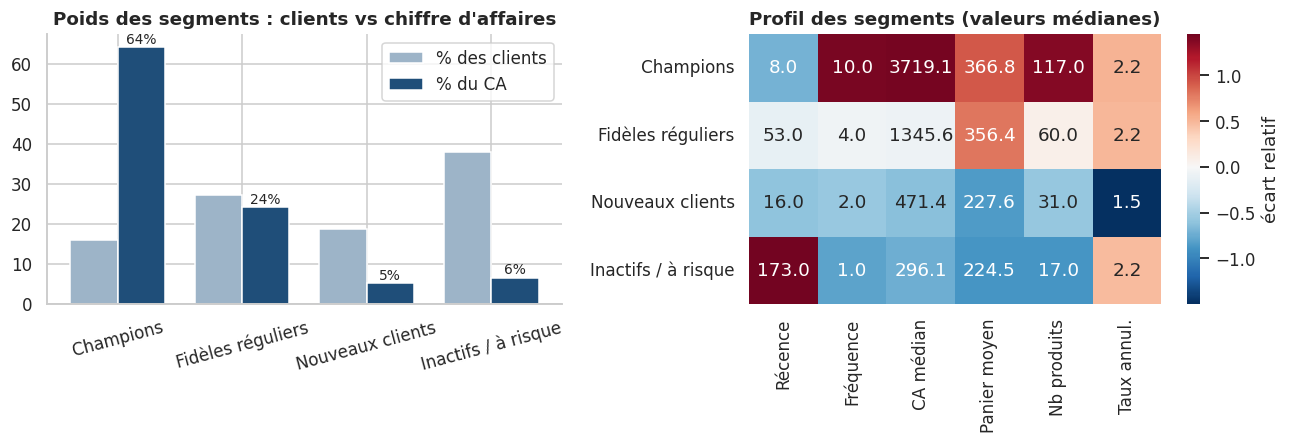

In [27]:
# Taille vs poids économique
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ordre = [NOMS[i] for i in sorted(NOMS)]
w = 0.38
xs = np.arange(len(ordre))
ax[0].bar(xs - w / 2, [prof.loc[i, "Part_clients_%"] for i in sorted(NOMS)], w, label="% des clients", color="#9DB4C8")
ax[0].bar(xs + w / 2, [prof.loc[i, "Part_CA_%"] for i in sorted(NOMS)], w, label="% du CA", color=PALETTE[0])
ax[0].set_xticks(xs); ax[0].set_xticklabels(ordre, rotation=15); ax[0].legend()
ax[0].set_title("Poids des segments : clients vs chiffre d'affaires")
for i, v in zip(xs, [prof.loc[i, "Part_CA_%"] for i in sorted(NOMS)]):
    ax[0].text(i + w / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
# Heatmap des profils (z-scores des médianes)
M = prof[["Recency_med", "Frequency_med", "Monetary_med", "PanierMoyen_med", "NbProduits_med", "TauxAnnulation_pct"]].copy()
M.columns = ["Récence", "Fréquence", "CA médian", "Panier moyen", "Nb produits", "Taux annul."]
Mz = (M - M.mean()) / M.std()
Mz.index = ordre
sns.heatmap(Mz, annot=M.round(1).values, fmt="", cmap="RdBu_r", center=0, ax=ax[1], cbar_kws={"label": "écart relatif"})
ax[1].set_yticklabels(ordre, rotation=0)
ax[1].set_title("Profil des segments (valeurs médianes)")
savefig("09_profil_segments")

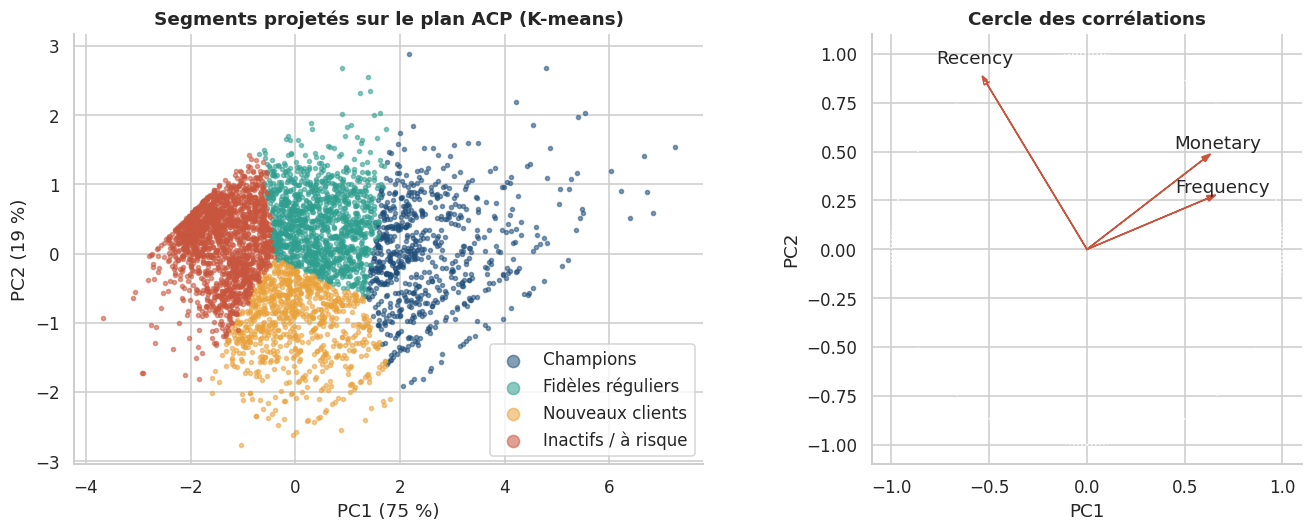

In [28]:
# Visualisation ACP
pca = PCA(n_components=3, random_state=SEED).fit(X)
P = pca.transform(X)
RES["pca_var_expl"] = [float(v) for v in pca.explained_variance_ratio_]
RES["pca_loadings"] = pd.DataFrame(pca.components_.T, index=core, columns=["PC1", "PC2", "PC3"]).round(3).to_dict()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i in sorted(NOMS):
    m = feat.Segment_id.values == i
    ax[0].scatter(P[m, 0], P[m, 1], s=7, alpha=.55, color=couleur_seg[NOMS[i]], label=NOMS[i])
ax[0].set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f} %)")
ax[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f} %)")
ax[0].legend(markerscale=3); ax[0].set_title("Segments projetés sur le plan ACP (K-means)")
for j, c in enumerate(core):
    ax[1].arrow(0, 0, pca.components_[0, j], pca.components_[1, j], head_width=.03, color=PALETTE[3])
    ax[1].text(pca.components_[0, j] * 1.12, pca.components_[1, j] * 1.12, c, ha="center")
ax[1].set_xlim(-1.1, 1.1); ax[1].set_ylim(-1.1, 1.1); ax[1].set_title("Cercle des corrélations")
ax[1].add_patch(plt.Circle((0, 0), 1, fill=False, ls=":"))
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_aspect("equal")
savefig("10_acp_segments")

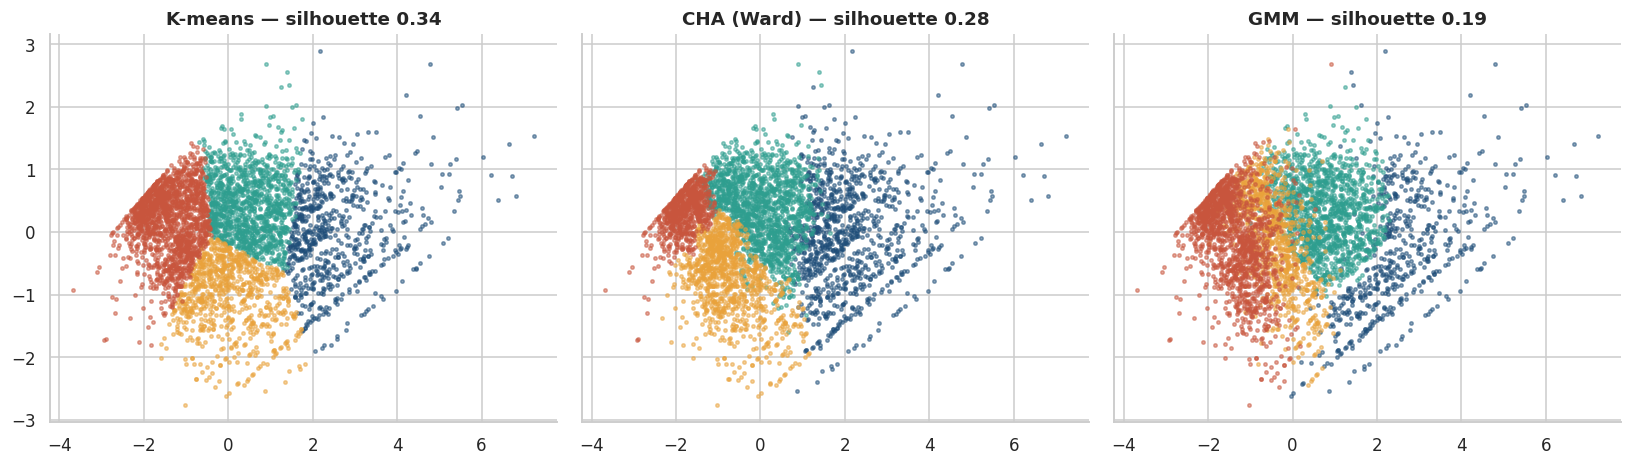

In [29]:
# Comparaison visuelle des trois méthodes dans le plan ACP
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for a, (nom, l) in zip(ax, lab.items()):
    for k in range(K_FINAL):
        a.scatter(P[l == k, 0], P[l == k, 1], s=5, alpha=.5, color=PALETTE[k])
    a.set_title(f"{nom} — silhouette {silhouette_score(X, l):.2f}")
savefig("11_comparaison_methodes_acp")

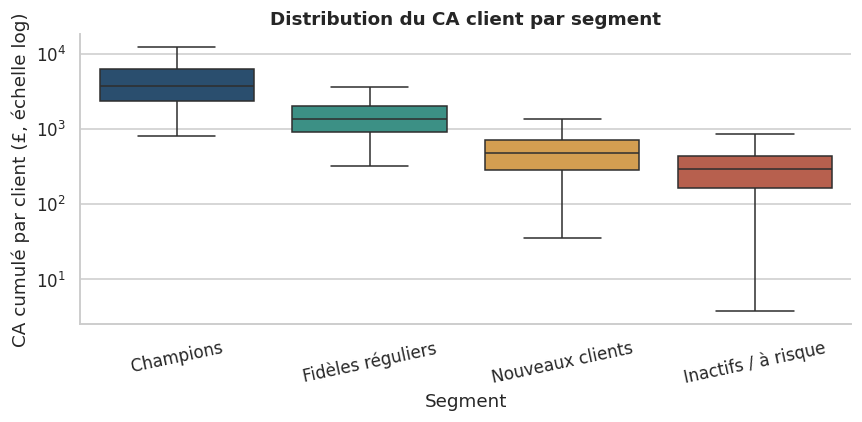

In [30]:
# Concentration du CA par segment (Lorenz) et indicateurs de risque
RES["ca_top_segment_%"] = float(prof.loc[0, "Part_CA_%"])
RES["clients_top_segment_%"] = float(prof.loc[0, "Part_clients_%"])
dist_recence = feat.groupby("Segment")["Recency"].apply(list)
plt.figure(figsize=(8, 4))
sns.boxplot(data=feat, x="Segment", y="Monetary", order=ordre, palette=[couleur_seg[o] for o in ordre], showfliers=False)
plt.yscale("log"); plt.xticks(rotation=12); plt.ylabel("CA cumulé par client (£, échelle log)")
plt.title("Distribution du CA client par segment")
savefig("12_boxplot_ca_segment")

## 10. Validation temporelle : les segments prédisent-ils la valeur future ?
Principe : on construit les segments **uniquement avec les achats jusqu'au 30/09/2011**, puis on observe le
comportement des clients du 01/10/2011 au 09/12/2011 (période *non utilisée* pour construire les segments).
→ évite la fuite de données (data leakage) et vérifie la valeur *prédictive* des segments.

        Clients  Recency_med  Frequency_med  Monetary_med  Taux_reachat  \
seg_id                                                                    
0           530         11.0            9.0        3195.3          89.2   
1          1030         64.0            3.0        1065.6          58.2   
2           603          8.0            2.0         560.4          51.4   
3          1450        163.0            1.0         249.5          31.4   

        CA_futur_moy  CA_futur_tot  Part_CA_futur_%  
seg_id                                               
0             2413.6     1279197.0             56.5  
1              425.6      438377.4             19.4  
2              292.2      176224.8              7.8  
3              255.0      369806.5             16.3  


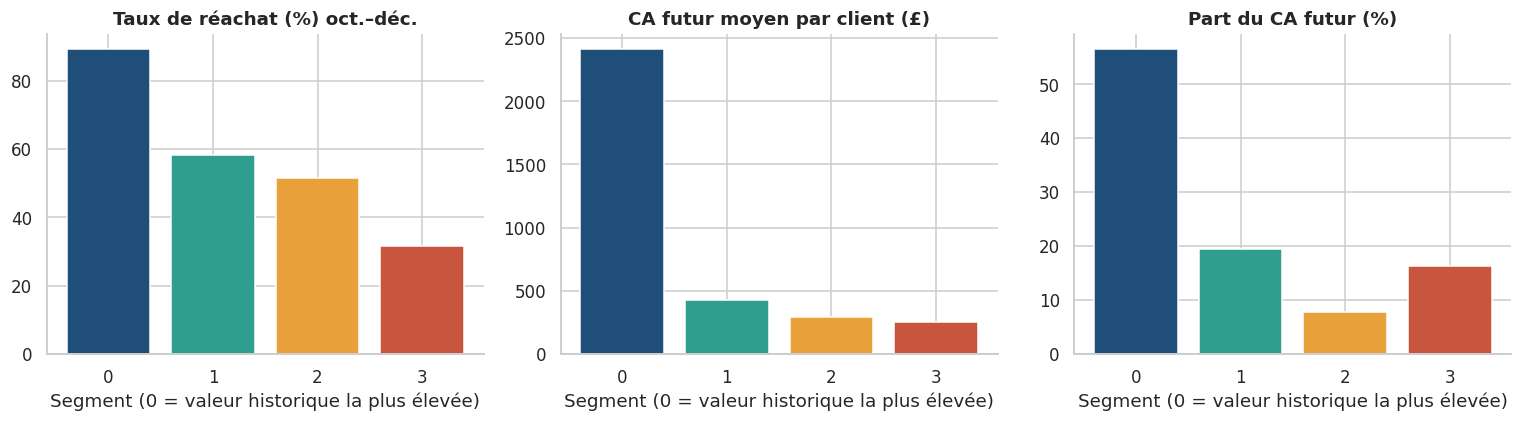

In [32]:
CUT = pd.Timestamp("2011-10-01")
ventes["InvoiceDate"] = pd.to_datetime(ventes["InvoiceDate"])
annul["InvoiceDate"] = pd.to_datetime(annul["InvoiceDate"])

v_tr, a_tr = ventes[ventes.InvoiceDate < CUT], annul[annul.InvoiceDate < CUT]
f_tr = construire_features(v_tr, a_tr, CUT)
X_tr, sc_tr = preparer(f_tr, core)
km_tr = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(X_tr)
f_tr["seg_id"] = reordonner(km_tr.labels_, f_tr)
futur = ventes[ventes.InvoiceDate >= CUT].groupby("CustomerID").Montant.sum()
f_tr["CA_futur"] = futur.reindex(f_tr.index).fillna(0)
f_tr["Actif_futur"] = (f_tr.CA_futur > 0).astype(int)
prof_tr = f_tr.groupby("seg_id").agg(Clients=("Monetary", "size"), Recency_med=("Recency", "median"),
                                     Frequency_med=("Frequency", "median"), Monetary_med=("Monetary", "median"),
                                     Taux_reachat=("Actif_futur", "mean"), CA_futur_moy=("CA_futur", "mean"),
                                     CA_futur_tot=("CA_futur", "sum"))
prof_tr["Part_CA_futur_%"] = 100 * prof_tr.CA_futur_tot / prof_tr.CA_futur_tot.sum()
prof_tr["Taux_reachat"] *= 100
print(prof_tr.round(1))
RES["validation_temporelle"] = prof_tr.round(2).reset_index().to_dict(orient="records")
RES["validation_n_train"] = int(len(f_tr))
# Corrélation de rang entre le score de segment (0 = meilleur) et le CA futur
from scipy.stats import spearmanr
rho, pval = spearmanr(f_tr.seg_id, f_tr.CA_futur)
RES["spearman_segment_vs_CA_futur"] = [float(rho), float(pval)]

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sg = prof_tr.index
ax[0].bar([str(s) for s in sg], prof_tr.Taux_reachat, color=PALETTE[:K_FINAL]); ax[0].set_title("Taux de réachat (%) oct.–déc.")
ax[1].bar([str(s) for s in sg], prof_tr.CA_futur_moy, color=PALETTE[:K_FINAL]); ax[1].set_title("CA futur moyen par client (£)")
ax[2].bar([str(s) for s in sg], prof_tr["Part_CA_futur_%"], color=PALETTE[:K_FINAL]); ax[2].set_title("Part du CA futur (%)")
for a in ax: a.set_xlabel("Segment (0 = valeur historique la plus élevée)")
savefig("13_validation_temporelle")

## 11. Exports et recommandations opérationnelles

In [33]:
export = feat[["Recency", "Frequency", "Monetary", "AvgBasket", "NbProducts", "ReturnRate", "Segment_id", "Segment",
               "Segment_CHA_id", "Segment_GMM_id"]].round(2)
export.to_csv(f"{OUT_DIR}/clients_segmentes.csv")
prof.round(2).to_csv(f"{OUT_DIR}/profil_segments.csv")
prof_tr.round(2).to_csv(f"{OUT_DIR}/validation_temporelle.csv")
with open(f"{OUT_DIR}/resultats.json", "w", encoding="utf-8") as fh:
    json.dump(RES, fh, ensure_ascii=False, indent=1, default=str)
print("Exports écrits dans", OUT_DIR)

Exports écrits dans outputs


## 12. Limites et précautions
* **Données non identifiées (≈ 25 % des lignes sans CustomerID)** : la segmentation ne couvre que les clients identifiés ;
  biais possible si les clients anonymes se comportent différemment.
* **Période courte (12 mois) et saisonnalité de Noël** ; décembre 2011 est tronqué. La récence est donc sensible à la date de référence.
* **Représentativité** : 1 seul commerçant, ~85 % du CA au Royaume-Uni ; clients souvent des revendeurs (B2B) → valeurs extrêmes.
* **Valeur historique ≠ valeur future** : le CA cumulé n'est pas une CLV ; la validation temporelle (section 10) n'est qu'un test indicatif.
* **Clustering non supervisé** : pas de « vérité terrain » ; la qualité s'apprécie via stabilité, cohérence métier et validation externe.
* Projet pédagogique : ne pas utiliser tel quel pour des décisions financières réelles.